In [ ]:
from pathlib import Path

root = Path("/content/drone_dataset/extracted/Database1/Database1")

images = list(root.glob("*.JPEG"))
image_stems = {p.stem for p in images}
label_stems = {p.stem for p in root.glob("*.txt")}

missing = image_stems - label_stems
empty = []
invalid = []

for p in root.glob("*.txt"):
    content = p.read_text().strip()

    if not content:
        empty.append(p.name)
        continue

    for line in content.splitlines():
        parts = line.split()
        try:
            values = [float(v) for v in parts]
            if len(values) != 5 or values[0] != 0 or not all(
                0 <= v <= 1 for v in values[1:]
            ) or values[3] <= 0 or values[4] <= 0:
                invalid.append((p.name, line))
        except ValueError:
            invalid.append((p.name, line))

print("Images:", len(images))
print("Images without label files:", len(missing))
print("Empty label files:", len(empty))
print("Invalid annotations:", len(invalid))
print("Examples of empty labels:", empty[:10])
print("Examples of invalid labels:", invalid[:5])

Images: 4012
Images without label files: 2
Empty label files: 1145
Invalid annotations: 0
Examples of empty labels: ['video632.txt', 'video19_2514.txt', 'video18_87.txt', 'video19_2994.txt', 'video17_669.txt', 'video18_694.txt', 'video19_2955.txt', '250.txt', 'video18_3014.txt', 'video19_930.txt']
Examples of invalid labels: []


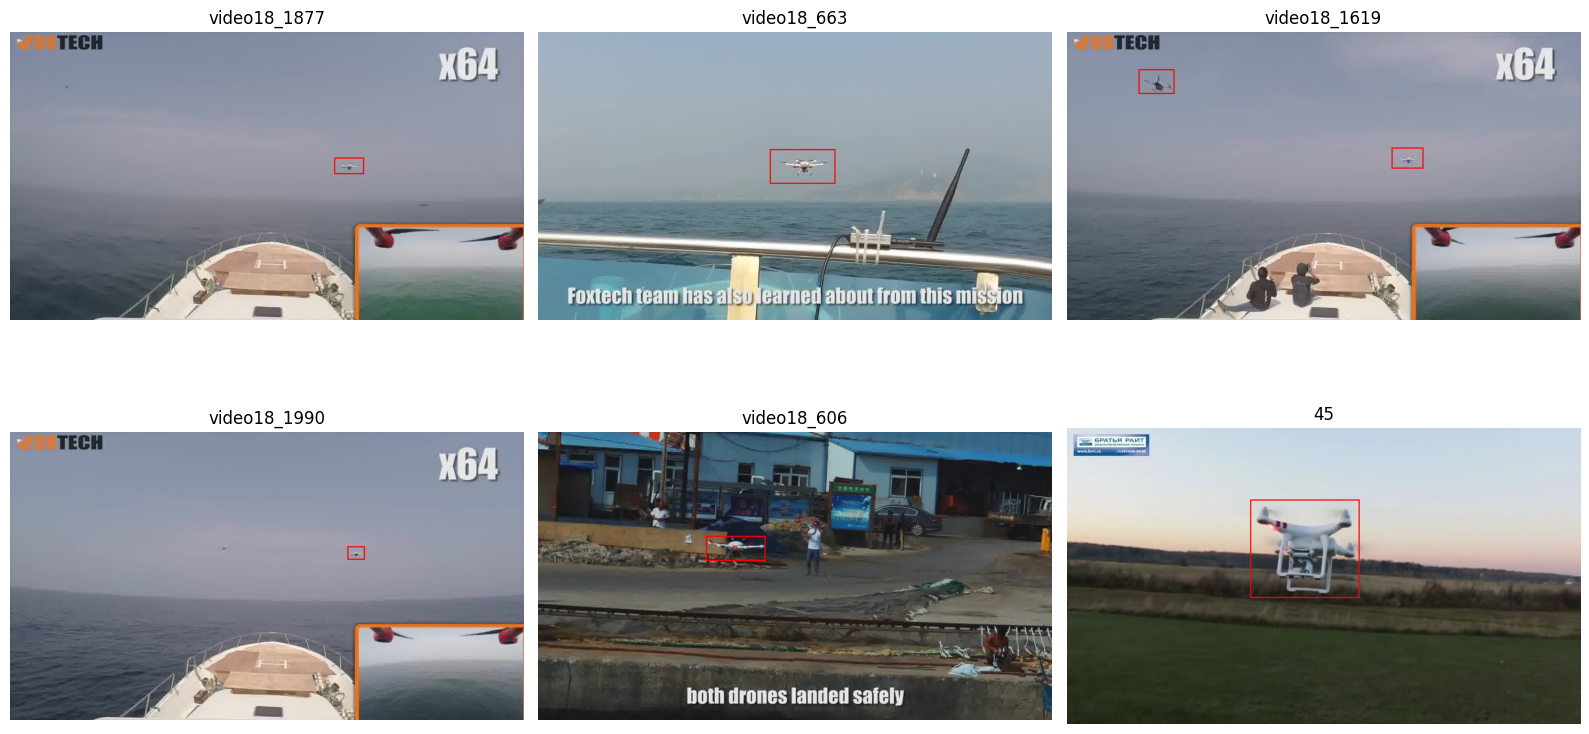

In [ ]:
from pathlib import Path
from PIL import Image, ImageDraw
import random
import matplotlib.pyplot as plt

root = Path("/content/drone_dataset/extracted/Database1/Database1")

labels = [
    p for p in root.glob("*.txt")
    if p.read_text().strip()
    and (root / f"{p.stem}.JPEG").exists()
]

samples = random.sample(labels, min(6, len(labels)))
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, label in zip(axes.flat, samples):
    img = Image.open(root / f"{label.stem}.JPEG").convert("RGB")
    draw = ImageDraw.Draw(img)
    w, h = img.size

    for line in label.read_text().strip().splitlines():
        cls, xc, yc, bw, bh = map(float, line.split())
        x1 = (xc - bw / 2) * w
        y1 = (yc - bh / 2) * h
        x2 = (xc + bw / 2) * w
        y2 = (yc + bh / 2) * h
        draw.rectangle([x1, y1, x2, y2], outline="red", width=3)

    ax.imshow(img)
    ax.set_title(label.stem)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
import random
import shutil

src = Path("/content/drone_dataset/extracted/Database1/Database1")
dst = Path("/content/drone_yolo")

# Use images that have non-empty annotation files for this first run.
images = [
    p for p in src.glob("*.JPEG")
    if (src / f"{p.stem}.txt").exists()
    and (src / f"{p.stem}.txt").read_text().strip()
]

random.seed(42)
random.shuffle(images)

split_idx = int(0.8 * len(images))
splits = {
    "train": images[:split_idx],
    "val": images[split_idx:]
}

for split_name, split_images in splits.items():
    img_dir = dst / split_name / "images"
    label_dir = dst / split_name / "labels"
    img_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    for img in split_images:
        shutil.copy2(img, img_dir / img.name)
        shutil.copy2(
            src / f"{img.stem}.txt",
            label_dir / f"{img.stem}.txt"
        )

yaml_text = (
    f"path: {dst}\n"
    "train: train/images\n"
    "val: val/images\n"
    "names:\n"
    "  0: drone\n"
)

(dst / "data.yaml").write_text(yaml_text)

print("Training images:", len(splits["train"]))
print("Validation images:", len(splits["val"]))
print("YAML exists:", (dst / "data.yaml").exists())
print((dst / "data.yaml").read_text())

Training images: 2292
Validation images: 573
YAML exists: True
path: /content/drone_yolo
train: train/images
val: val/images
names:
  0: drone



In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26m.pt")

results = model.train(
    data="/content/drone_yolo/data.yaml",
    epochs=10,
    imgsz=960,
    batch=8,
    patience=10,
    device=0,
    workers=2,
    project="/content/runs",
    name="drone_detection_10ep",
    seed=42
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drone_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=drone_detection_10ep, nbs=64, nms=None, opset=None, optimize

In [5]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
!nvidia-smi
!pip install -q ultralytics kaggle

/bin/bash: line 1: nvidia-smi: command not found
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 7.6 MB/s eta 0:00:00


In [6]:

from pathlib import Path

from google.colab import drive
drive.mount("/content/drive")

candidates = [
    Path("/content/runs/drone_detection_10ep"),
    Path("/content/drive/MyDrive/FPV_Drone_AI/drone_detection_10ep"),
    Path("/content/drive/MyDrive/FPV_Drone_AI"),
]

for path in candidates:
    print(f"\n{path} — exists: {path.exists()}")
    if path.exists():
        for item in list(path.iterdir())[:15]:
            print("  ", item.name)

print("\nSearching Drive for trained weights...")
drive_root = Path("/content/drive/MyDrive")
matches = list(drive_root.rglob("best.pt"))

for p in matches[:20]:
    print(p, f"({p.stat().st_size / (1024*1024):.1f} MB)")

if not matches:
    print("No best.pt found in Drive. Check whether the model was saved elsewhere.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

/content/runs/drone_detection_10ep — exists: False

/content/drive/MyDrive/FPV_Drone_AI/drone_detection_10ep — exists: True
   args.yaml
   labels.jpg
   train_batch0.jpg
   train_batch1.jpg
   train_batch2.jpg
   weights
   results.csv
   val_batch1_labels.jpg
   val_batch0_labels.jpg
   val_batch1_pred.jpg
   val_batch0_pred.jpg
   val_batch2_labels.jpg
   val_batch2_pred.jpg
   BoxPR_curve.png
   BoxP_curve.png

/content/drive/MyDrive/FPV_Drone_AI — exists: True
   drone_detection_10ep
   drone_yolo
   test_results

Searching Drive for trained weights...
/content/drive/MyDrive/FPV_Drone_AI/drone_detection_10ep/weights/best.pt (42.0 MB)


In [ ]:
import shutil

DATASET_DIR = DRIVE_DIR / "drone_yolo"

if not DATASET_DIR.exists():
    shutil.copytree("/content/drone_yolo", DATASET_DIR)
    print("Dataset backed up to Drive!")
else:
    print("Dataset backup already exists:", DATASET_DIR)

Dataset backed up to Drive!


# TRAINED TILL HERE

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [7]:
from pathlib import Path
from ultralytics import YOLO

DRIVE_DIR = Path("/content/drive/MyDrive/FPV_Drone_AI")
RUN_DIR = DRIVE_DIR / "drone_detection_10ep"
MODEL_PATH = RUN_DIR / "weights" / "best.pt"

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"

model = YOLO(str(MODEL_PATH))

print("Drone detection model loaded successfully!")
print("Model:", MODEL_PATH)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Drone detection model loaded successfully!
Model: /content/drive/MyDrive/FPV_Drone_AI/drone_detection_10ep/weights/best.pt


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drone detection model loaded!
Upload an image or video to test...


Saving original.jpg to original.jpg


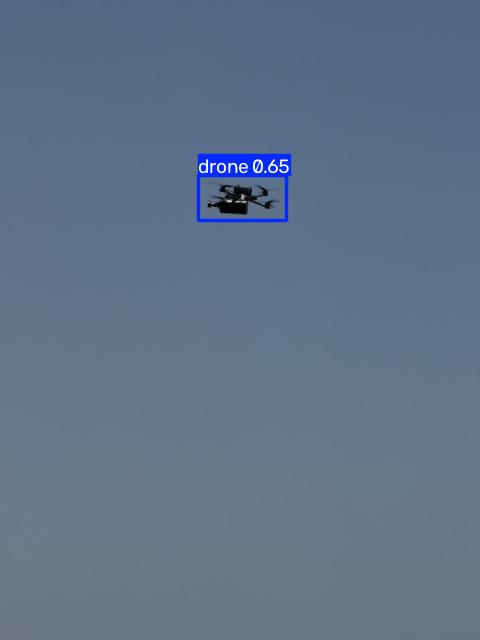


Detections:
drone: 65.4% confidence

Output saved permanently to:
/content/drive/MyDrive/FPV_Drone_AI/test_results/detected_original.jpg


In [8]:

from google.colab import drive, files
from ultralytics import YOLO
from IPython.display import display, Video
from pathlib import Path
from PIL import Image
import cv2
import numpy as np

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Load your trained drone detection model
BASE_DIR = Path("/content/drive/MyDrive/FPV_Drone_AI")
MODEL_PATH = BASE_DIR / "drone_detection_10ep/weights/best.pt"
OUTPUT_DIR = BASE_DIR / "test_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

model = YOLO(str(MODEL_PATH))
print("Drone detection model loaded!")

# 3. Upload an image or video
print("Upload an image or video to test...")
uploaded = files.upload()

if not uploaded:
    raise ValueError("No file uploaded.")

filename = next(iter(uploaded))
input_path = Path(filename)
ext = input_path.suffix.lower()

image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
video_exts = {".mp4", ".avi", ".mov", ".mkv", ".webm"}

# 4. Run detection
if ext in image_exts:
    result = model.predict(
        source=str(input_path),
        conf=0.25,
        imgsz=960,
        verbose=False
    )[0]

    annotated = result.plot()
    output_path = OUTPUT_DIR / f"detected_{input_path.name}"
    Image.fromarray(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)).save(output_path)

    display(Image.open(output_path))

    print("\nDetections:")
    if result.boxes is None or len(result.boxes) == 0:
        print("No drones detected.")
    else:
        for box in result.boxes:
            label = model.names[int(box.cls[0])]
            confidence = float(box.conf[0])
            print(f"{label}: {confidence:.1%} confidence")

elif ext in video_exts:
    output_path = OUTPUT_DIR / f"detected_{input_path.stem}.mp4"

    cap = cv2.VideoCapture(str(input_path))
    if not cap.isOpened():
        raise ValueError("Could not open the uploaded video.")

    fps = cap.get(cv2.CAP_PROP_FPS)
    fps = fps if fps and fps > 0 else 30
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()

    # Stream predictions to avoid loading every frame into memory
    writer = cv2.VideoWriter(
        str(output_path),
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (width, height)
    )

    try:
        for result in model.predict(
            source=str(input_path),
            conf=0.25,
            imgsz=960,
            stream=True,
            verbose=False
        ):
            frame = result.plot()
            frame = cv2.resize(frame, (width, height))
            writer.write(frame)
    finally:
        writer.release()

    display(Video(str(output_path), embed=True, width=720))
    print("Processed video saved!")

else:
    raise ValueError(
        f"Unsupported format: {ext}. Upload JPG, PNG, MP4, AVI, MOV, or MKV."
    )

print(f"\nOutput saved permanently to:\n{output_path}")
